# Seafloor clustering (PCA, k-means, GMM)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
import seafloor as sf

lon, lat, z, ship, dx, dy = sf.load_clean()
extent = [lon[0], lon[-1], lat[0], lat[-1]]; aspect = 1 / np.cos(np.deg2rad(lat.mean()))
shade = sf.hillshade(np.where(np.isnan(z), np.nanmedian(z), z), dx, dy)
rng = np.random.default_rng(42)

In [2]:
F = sf.compute_features(z, dx, dy)
ok = ~np.isnan(F).any(axis=-1)
X_all = F[ok]
print(f"{X_all.shape[0]:,} cells x {X_all.shape[1]} features\n")
for k, name in enumerate(sf.FEATURES):
    q = np.percentile(X_all[:, k], [5, 50, 95])
    print(f"  {name:10s} 5%/50%/95%: {q[0]:9.2f} {q[1]:9.2f} {q[2]:9.2f}   ({sf.FEATURE_INFO[name]})")

2,485,355 cells x 7 features

  depth      5%/50%/95%:  -7902.31  -4397.80  -1985.27   (elevation (m, negative = deep))
  slope      5%/50%/95%:      0.23      2.51     12.22   (slope angle (°) after 1 km smoothing)
  roughness  5%/50%/95%:      5.79     51.62    205.93   (RMS of small-scale bumps (< ~5 km) in a 5 km window (m))
  bpi_fine   5%/50%/95%:    -59.85     -1.90     68.81   (height above the average of the surrounding 5 km (m))
  bpi_broad  5%/50%/95%:   -292.00     -7.67    368.34   (height above the average of the surrounding 20 km (m))


  curv_min   5%/50%/95%:     -3.63     -0.27      0.45   (Hessian eigenvalue λ1 (most-bent direction), ×1e5 per m)
  curv_max   5%/50%/95%:     -0.62      0.38      3.33   (Hessian eigenvalue λ2 (least-bent direction), ×1e5 per m)


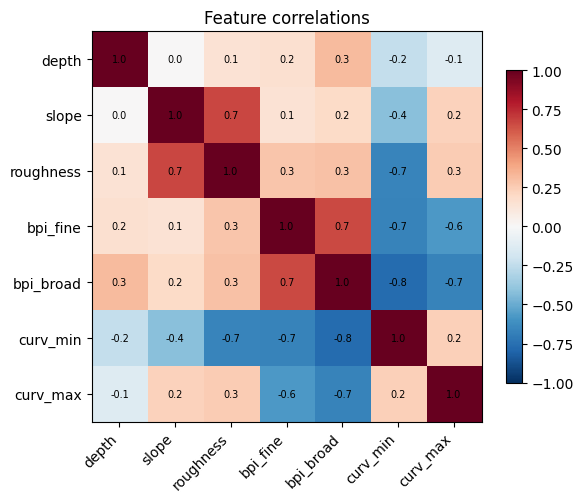

In [3]:
idx = rng.choice(len(X_all), 30_000, replace=False)
scaler = StandardScaler().fit(X_all[idx])
Xs = scaler.transform(X_all[idx])

corr = np.corrcoef(Xs.T)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(7), sf.FEATURES, rotation=45, ha="right"); ax.set_yticks(range(7), sf.FEATURES)
for i in range(7):
    for j in range(7): ax.text(j, i, f"{corr[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Feature correlations")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "05_correlation.png", dpi=200); plt.show()

Variance explained by each component: [0.455 0.267 0.133 0.062 0.048 0.027 0.009]
First 2 components: 72%   first 3: 86%

Loadings (how much each feature contributes):
                 depth      slope  roughness   bpi_fine  bpi_broad   curv_min   curv_max
  PC1           -0.20      -0.25      -0.34      -0.45      -0.49       0.51       0.27
  PC2           -0.08       0.53       0.52      -0.20      -0.22      -0.13       0.57
  PC3            0.95      -0.13       0.02      -0.21      -0.01       0.04       0.16


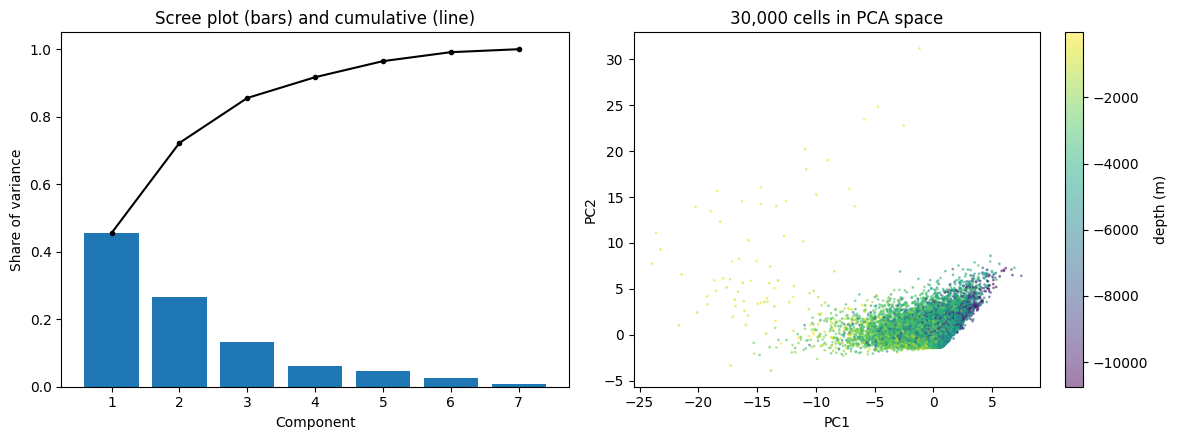

In [4]:
pca = PCA().fit(Xs)
ev = pca.explained_variance_ratio_
print("Variance explained by each component:", np.round(ev, 3))
print(f"First 2 components: {ev[:2].sum():.0%}   first 3: {ev[:3].sum():.0%}\n")
print("Loadings (how much each feature contributes):")
print(" " * 11 + "".join(f"{n:>11s}" for n in sf.FEATURES))
for i in range(3):
    print(f"  PC{i+1}     " + "".join(f"{v:11.2f}" for v in pca.components_[i]))

P = pca.transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(range(1, 8), ev); axes[0].plot(range(1, 8), np.cumsum(ev), "k.-")
axes[0].set(xlabel="Component", ylabel="Share of variance", title="Scree plot (bars) and cumulative (line)")
sc = axes[1].scatter(P[:, 0], P[:, 1], s=1, c=X_all[idx, 0], cmap="viridis", alpha=0.5)
fig.colorbar(sc, ax=axes[1], label="depth (m)")
axes[1].set(xlabel="PC1", ylabel="PC2", title="30,000 cells in PCA space")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "05_pca.png", dpi=200); plt.show()

k= 2  silhouette 0.488   GMM BIC 303,278


k= 3  silhouette 0.405   GMM BIC 257,219


k= 4  silhouette 0.389   GMM BIC 234,109


k= 5  silhouette 0.356   GMM BIC 224,625


k= 6  silhouette 0.345   GMM BIC 215,452


k= 7  silhouette 0.310   GMM BIC 210,162


k= 8  silhouette 0.266   GMM BIC 208,067


k= 9  silhouette 0.275   GMM BIC 203,627


k=10  silhouette 0.274   GMM BIC 198,191

Best k by silhouette (k ≥ 3): 3    best k by BIC: 10


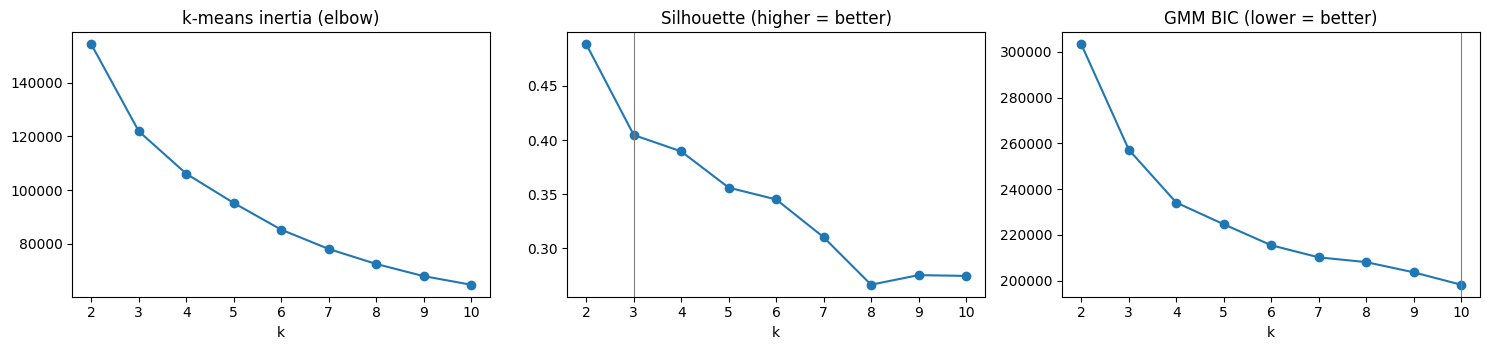

In [5]:
K = range(2, 11)
sil, bic, inertia = [], [], []
sub = Xs[:10_000]
for k in K:
    km = KMeans(k, n_init=10, random_state=0).fit(Xs)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(sub, km.predict(sub)))
    bic.append(GaussianMixture(k, covariance_type="full", random_state=0, n_init=2).fit(Xs).bic(Xs))
    print(f"k={k:2d}  silhouette {sil[-1]:.3f}   GMM BIC {bic[-1]:,.0f}")

k_sil = list(K)[int(np.argmax(sil[1:])) + 1]
k_bic = list(K)[int(np.argmin(bic))]
print(f"\nBest k by silhouette (k ≥ 3): {k_sil}    best k by BIC: {k_bic}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(K, inertia, "o-"); axes[0].set(title="k-means inertia (elbow)", xlabel="k")
axes[1].plot(K, sil, "o-"); axes[1].axvline(k_sil, c="gray", lw=0.8); axes[1].set(title="Silhouette (higher = better)", xlabel="k")
axes[2].plot(K, bic, "o-"); axes[2].axvline(k_bic, c="gray", lw=0.8); axes[2].set(title="GMM BIC (lower = better)", xlabel="k")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "05_choose_k.png", dpi=200); plt.show()

In [6]:
K_USE = k_sil
km = KMeans(K_USE, n_init=10, random_state=0).fit(Xs)
labels = np.full(z.shape, -1, dtype=np.int16)
labels[ok] = km.predict(scaler.transform(X_all))

centers = scaler.inverse_transform(km.cluster_centers_)
order = np.argsort(centers[:, 0]); remap = np.empty_like(order); remap[order] = np.arange(K_USE)
labels[ok] = remap[labels[ok]]; centers = centers[order]
cz = km.cluster_centers_[order]

def describe(zrow):
    words = {"depth": ("deep", "shallow"), "slope": ("gentle", "steep"), "roughness": ("smooth", "rough"),
             "bpi_fine": ("locally low", "locally high"), "bpi_broad": ("in a basin/trench", "on a high/rise"),
             "curv_min": ("sharply convex", "not convex"), "curv_max": ("not concave", "sharply concave")}
    top = np.argsort(-np.abs(zrow))[:3]
    return ", ".join(words[sf.FEATURES[t]][int(zrow[t] > 0)] for t in top if abs(zrow[t]) > 0.4) or "flat, gentle, smooth (plains)"

names = [describe(r) for r in cz]
np.save(sf.DATA_DIR / "clusters.npy", labels)

w = np.cos(np.deg2rad(lat))[:, None] * np.ones_like(z)
print(f"{'#':>2s} {'area':>6s} {'ship%':>6s} " + "".join(f"{n:>10s}" for n in sf.FEATURES) + "   description")
for c in range(K_USE):
    m = labels == c
    print(f"{c:2d} {(w*m).sum()/(w*ok).sum():6.1%} {(m & ship).sum()/m.sum():6.0%} "
          + "".join(f"{v:10.1f}" for v in centers[c]) + f"   {names[c]}")

 #   area  ship%      depth     slope roughness  bpi_fine bpi_broad  curv_min  curv_max   description
 0  17.6%    68%    -5278.1       7.0     127.8     -40.3    -212.2      -0.3       2.8   sharply concave, in a basin/trench, locally low
 1  71.6%    58%    -4458.9       2.3      39.9      -0.6      -3.9      -0.4       0.4   flat, gentle, smooth (plains)
 2  10.8%    64%    -3473.2       9.1     201.7      68.1     389.5      -4.0      -0.3   sharply convex, on a high/rise, locally high


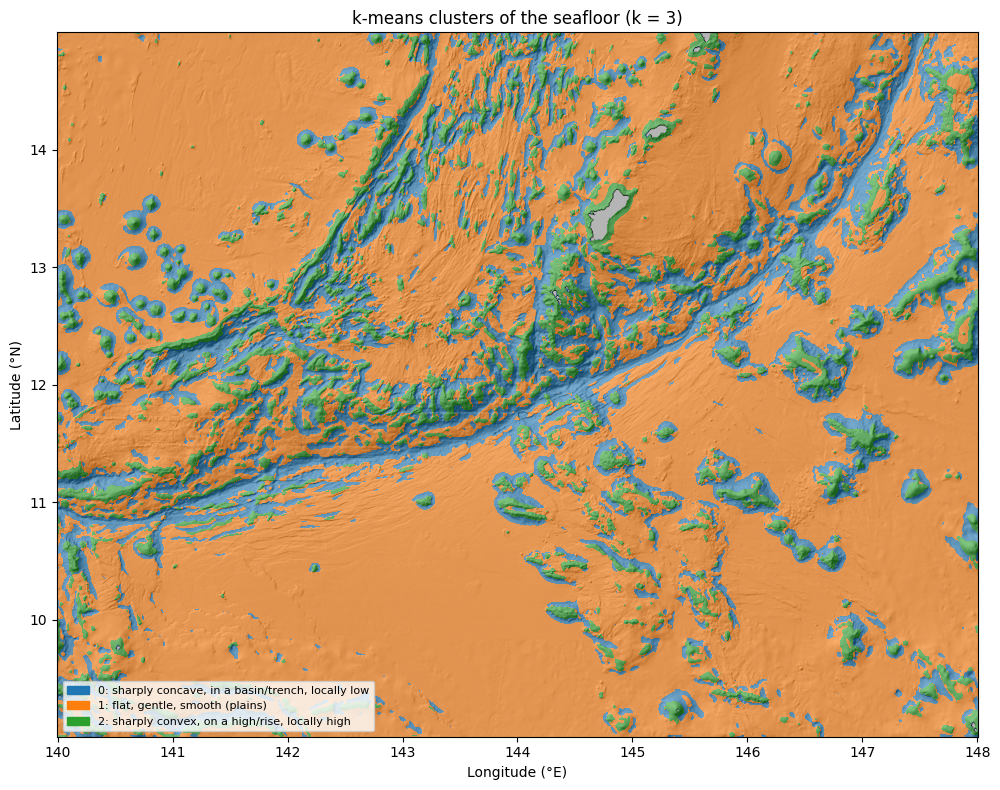

In [7]:
cmap = ListedColormap(plt.cm.tab10.colors[:K_USE])
fig, ax = plt.subplots(figsize=(11, 8))
ax.imshow(shade, extent=extent, origin="lower", cmap="gray", aspect=aspect)
ax.imshow(np.where(labels >= 0, labels, np.nan), extent=extent, origin="lower", cmap=cmap,
          vmin=-0.5, vmax=K_USE - 0.5, alpha=0.6, aspect=aspect, interpolation="nearest")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=cmap(c)) for c in range(K_USE)],
          [f"{c}: {names[c]}" for c in range(K_USE)], loc="lower left", fontsize=8)
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)", title=f"k-means clusters of the seafloor (k = {K_USE})")
fig.tight_layout(); fig.savefig(sf.FIG_DIR / "05_cluster_map.png", dpi=200); plt.show()

In [8]:
from scipy import ndimage
DX = float(np.mean(dx)); zf = np.where(np.isnan(z), np.nanmedian(z), z)
z2 = ndimage.gaussian_filter(zf, 2000 / DX)
zy, zx = np.gradient(z2, dy, DX); zyy, zyx = np.gradient(zy, dy, DX); zxy, zxx = np.gradient(zx, dy, DX)
b = 0.5 * (zxy + zyx); mm = 0.5 * (zxx + zyy); rr = np.sqrt((0.5 * (zxx - zyy)) ** 2 + b ** 2)
l1, l2, t = mm - rr, mm + rr, 1e-5
shape = np.zeros(z.shape, int)
shape[(l1 < -t) & (l2 < -t)] = 1; shape[(l1 > t) & (l2 > t)] = 2
shape[(l1 < -t) & (np.abs(l2) <= t)] = 3; shape[(np.abs(l1) <= t) & (l2 > t)] = 4; shape[(l1 < -t) & (l2 > t)] = 5
SH = ["planar", "peak", "pit", "ridge", "valley", "saddle"]

print("(a) Share of each cluster by curvature class (rows sum to 100%)")
print(" " * 4 + "".join(f"{s:>8s}" for s in SH))
for c in range(K_USE):
    m = labels == c
    print(f"{c:3d} " + "".join(f"{(shape[m] == s).mean():8.0%}" for s in range(6)))

print("\n(b) Ship-measured share per cluster (whole region: {:.0%})".format(ship[ok].mean()))
for c in range(K_USE):
    m = labels == c; s = ship[m].mean()
    flag = "  ← mostly one data source" if s > 0.85 or s < 0.25 else ""
    print(f"  cluster {c}: {s:5.0%}{flag}")

(a) Share of each cluster by curvature class (rows sum to 100%)
      planar    peak     pit   ridge  valley  saddle
  0       4%      0%      8%      1%     67%     19%
  1      72%      0%      0%     12%     12%      3%
  2       1%     27%      0%     58%      0%     14%

(b) Ship-measured share per cluster (whole region: 60%)
  cluster 0:   68%
  cluster 1:   58%
  cluster 2:   64%


In [9]:
print("KEY NUMBERS")
print(f"  PCA: first 2 components explain {ev[:2].sum():.0%}, first 3 explain {ev[:3].sum():.0%}")
print(f"  Best k: silhouette {k_sil} (score {max(sil[1:]):.2f}), BIC {k_bic}")
for c in range(K_USE):
    m = labels == c
    print(f"  cluster {c}: {(w*m).sum()/(w*ok).sum():5.1%} of area, {ship[m].mean():4.0%} ship — {names[c]}")

KEY NUMBERS
  PCA: first 2 components explain 72%, first 3 explain 86%
  Best k: silhouette 3 (score 0.40), BIC 10
  cluster 0: 17.6% of area,  68% ship — sharply concave, in a basin/trench, locally low
  cluster 1: 71.6% of area,  58% ship — flat, gentle, smooth (plains)
  cluster 2: 10.8% of area,  64% ship — sharply convex, on a high/rise, locally high
